# Assignment 3: Neural Machine Translation with LSTM and Attention Mechanisms
**Natural Language Processing — Fall 2026**  
**Institution:** Alexandria National University  
**Student Name:** Mohamed Baz  
**Repository:** [https://github.com/FekyBaz/nlp-en-de-seq2seq-attention](https://github.com/FekyBaz/nlp-en-de-seq2seq-attention)

---

## 📌 Executive Summary
In this notebook, we build, train, evaluate, and compare two Sequence-to-Sequence (Seq2Seq) architectures for English-to-German Neural Machine Translation (NMT):
1. **Baseline Seq2Seq (LSTM without Attention)**: An Encoder LSTM compresses the variable-length source sentence into a single fixed-length context vector $(h_T, c_T)$, which initializes the Decoder LSTM to generate the target translation autoregressively.
2. **Seq2Seq with Bahdanau Attention**: A Bidirectional Encoder LSTM outputs hidden states for every source token. At each decoding step, an additive attention mechanism computes dynamic alignment weights ($\alpha_{t,s}$) over all encoder hidden states to form a time-varying context vector ($c_t$).

We conduct a multi-faceted evaluation covering:
- **Loss Convergence:** Training and validation loss curves across epochs.
- **Quantitative Metrics:** Corpus-level **BLEU-1 through BLEU-4** and **ROUGE-L**.
- **Sentence-Length Bottleneck Analysis:** Performance across short (3–6 words) vs. longer (12–18+ words) sentences to empirically demonstrate the fixed-vector information bottleneck.
- **Attention Visualizations:** 2D Attention Heatmaps ($\alpha_{t,s}$) demonstrating monotonic vs. off-diagonal syntactic alignments (e.g., German verb-final and compound noun structures).
- **Qualitative Error Analysis:** Side-by-side error categorization across failure modes.

In [1]:
import os
import math
import time
import random
import json
from typing import List, Tuple, Dict, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from IPython.display import Image, display

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from datasets import load_dataset
import sacrebleu
from rouge_score import rouge_scorer

# Import clean source modules
from src.data import (
    PAD_TOKEN, SOS_TOKEN, EOS_TOKEN, UNK_TOKEN,
    PAD_IDX, SOS_IDX, EOS_IDX, UNK_IDX,
    clean_text, tokenize_en, tokenize_de, Vocab,
    TranslationDataset, collate_fn, load_and_prepare_data, get_dataloaders
)
from src.models_baseline import BaselineEncoder, BaselineDecoder, Seq2SeqBaseline
from src.models_attention import BidirectionalEncoder, BahdanauAttention, AttentionDecoder, Seq2SeqAttention
from src.evaluate import translate_sentence_baseline, translate_sentence_attention, evaluate_metrics, evaluate_by_length
from src.visualize import plot_loss_curves, plot_attention_heatmap, plot_length_analysis

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[*] Running PyTorch version {torch.__version__} on device: {device}")


[*] Running PyTorch version 2.5.1+cpu on device: cpu


---
## 1. Dataset & Preprocessing Pipeline

### 1.1 Dataset: Multi30k (English-German)
We use the canonical **Multi30k** English-German parallel dataset. It contains paired descriptive captions of visual scenes, providing rich grammatical variety (prepositional phrases, color and size adjectives, compound nouns, and varying clause lengths).

### 1.2 Normalization and German Character Preservation
German orthography includes essential characters:
- **Umlauts:** $\ddot{a}, \ddot{o}, \ddot{u}$ (ä, ö, ü)
- **Eszett / Sharp S:** $\beta$ (ß)

These characters are semantically critical in German (e.g., *schon* [already] vs. *schön* [beautiful]; *Mutter* [mother] vs. *Mütter* [mothers]).
Our cleaning pipeline:
1. Normalizes Unicode into NFC (`unicodedata.normalize('NFC', text)`).
2. Lowercases text.
3. Separates punctuation marks cleanly with spaces.
4. Strips extraneous symbols while **strictly preserving German umlauts and ß**.

In [2]:
# Demonstrate normalization with German umlauts and Eszett
sample_de_raw = "Männer & Frauen genießen schöne Grüße in der Straße!"
print("Original German:", sample_de_raw)
print("Normalized German:", clean_text(sample_de_raw, lang="de"))
print("Tokenized German:", tokenize_de(sample_de_raw))

# Load Multi30k and prepare vocabularies
src_vocab, trg_vocab, raw_data = load_and_prepare_data(
    train_limit=10000,
    val_limit=1014,
    test_limit=1000,
    min_freq=2,
    max_len=40
)

print(f"\n[+] Source (EN) Vocab size: {len(src_vocab):,} tokens")
print(f"[+] Target (DE) Vocab size: {len(trg_vocab):,} tokens")
print(f"[+] Train pairs: {len(raw_data['train'][0]):,} | Val pairs: {len(raw_data['validation'][0]):,} | Test pairs: {len(raw_data['test'][0]):,}")


Original German: Männer & Frauen genießen schöne Grüße in der Straße!
Normalized German: männer frauen genießen schöne grüße in der straße !
Tokenized German: ['männer', 'frauen', 'genießen', 'schöne', 'grüße', 'in', 'der', 'straße', '!']



[+] Source (EN) Vocab size: 3,345 tokens
[+] Target (DE) Vocab size: 3,751 tokens
[+] Train pairs: 10,000 | Val pairs: 1,014 | Test pairs: 1,000


In [3]:
train_loader, val_loader, test_loader = get_dataloaders(
    src_vocab=src_vocab,
    trg_vocab=trg_vocab,
    raw_data=raw_data,
    batch_size=64,
    max_len=40
)

sample_batch = next(iter(train_loader))
print(f"[*] Batch src tensor shape: {sample_batch['src'].shape}")
print(f"[*] Batch trg tensor shape: {sample_batch['trg'].shape}")
print(f"[*] Raw English source sample: '{sample_batch['raw_en'][0]}'")
print(f"[*] Raw German target sample:  '{sample_batch['raw_de'][0]}'")


[*] Batch src tensor shape: torch.Size([64, 29])
[*] Batch trg tensor shape: torch.Size([64, 29])
[*] Raw English source sample: 'A man in a purple jacket has an expression on his face.'
[*] Raw German target sample:  'Ein Mann in einer violetten Jacke hat einen Ausdruck auf seinem Gesicht.'


---
## 2. Model 1: Baseline Seq2Seq (LSTM without Attention)

### Mathematical Formulation
1. **Encoder LSTM**:
   Maps input tokens $x = (x_1, \dots, x_S)$ to dense embeddings and processes them through an LSTM:
   $$(h_s^{enc}, c_s^{enc}) = \text{LSTM}(e_s, (h_{s-1}^{enc}, c_{s-1}^{enc}))$$
2. **Context Vector Bottleneck**:
   The entire source sequence information is compressed into the final hidden and cell state $(h_S^{enc}, c_S^{enc})$.
   The decoder is initialized with:
   $$h_0^{dec} = h_S^{enc}, \quad c_0^{dec} = c_S^{enc}$$
3. **Autoregressive Decoder**:
   Generates target tokens $y_t$ given previous token embedding $e_t^{trg}$ and previous states:
   $$(h_t^{dec}, c_t^{dec}) = \text{LSTM}(e_t^{trg}, (h_{t-1}^{dec}, c_{t-1}^{dec}))$$
   $$P(y_t \mid y_{<t}, x) = \text{softmax}(W_o h_t^{dec} + b_o)$$

In [4]:
EMB_DIM = 128
HID_DIM = 256
DROPOUT = 0.3

b_encoder = BaselineEncoder(
    vocab_size=len(src_vocab),
    emb_dim=EMB_DIM,
    hid_dim=HID_DIM,
    n_layers=1,
    dropout=DROPOUT,
    pad_idx=PAD_IDX,
)
b_decoder = BaselineDecoder(
    vocab_size=len(trg_vocab),
    emb_dim=EMB_DIM,
    hid_dim=HID_DIM,
    n_layers=1,
    dropout=DROPOUT,
    pad_idx=PAD_IDX,
)
baseline_model = Seq2SeqBaseline(b_encoder, b_decoder, device).to(device)

# Load best checkpoint
baseline_model.load_state_dict(torch.load("outputs/checkpoints/baseline_best.pt", map_location=device))
baseline_model.eval()

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"[*] Baseline Seq2Seq parameters: {count_parameters(baseline_model):,}")
print("[+] Successfully loaded best Baseline weights from outputs/checkpoints/baseline_best.pt")


[*] Baseline Seq2Seq parameters: 2,662,823
[+] Successfully loaded best Baseline weights from outputs/checkpoints/baseline_best.pt


C:\Users\laphouse\AppData\Local\Temp\ipykernel_35548\1507017529.py:24: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  baseline_model.load_state_dict(torch.load("outputs/check

---
## 3. Model 2: Seq2Seq with Bahdanau (Additive) Attention

### Mathematical Formulation
1. **Bidirectional Encoder**:
   Concatenates forward $\vec{h}_s$ and backward $\overleftarrow{h}_s$ hidden states:
   $$H_s = [\vec{h}_s; \overleftarrow{h}_s] \in \mathbb{R}^{2 \cdot d_{enc}}$$
   Initial decoder states: $s_0 = \tanh(W_{init} [\vec{h}_S; \overleftarrow{h}_1] + b_{init})$.
2. **Bahdanau Alignment Energy & Attention Weights**:
   $$e_{t, s} = v_a^\top \tanh(W_a s_{t-1} + U_a H_s)$$
   $$\alpha_{t, s} = \frac{\exp(e_{t, s})}{\sum_{k=1}^S \exp(e_{t, k})}$$
   *(Padded source positions are masked with $-\infty$ prior to softmax).*
3. **Dynamic Context Vector & Output**:
   $$c_t = \sum_{s=1}^S \alpha_{t, s} H_s$$
   $$(s_t, c_t^{dec}) = \text{LSTMCell}([e_t^{trg}; c_t], (s_{t-1}, c_{t-1}^{dec}))$$
   $$P(y_t \mid y_{<t}, x) = \text{softmax}(W_o [s_t; c_t; e_t^{trg}] + b_o)$$

In [5]:
a_encoder = BidirectionalEncoder(
    vocab_size=len(src_vocab),
    emb_dim=EMB_DIM,
    enc_hid_dim=HID_DIM // 2,  # 128 fwd + 128 bwd = 256 representation
    dec_hid_dim=HID_DIM,
    dropout=DROPOUT,
    pad_idx=PAD_IDX,
)
attention = BahdanauAttention(
    enc_hid_dim=HID_DIM // 2,
    dec_hid_dim=HID_DIM,
    attn_dim=HID_DIM // 2,
)
a_decoder = AttentionDecoder(
    vocab_size=len(trg_vocab),
    emb_dim=EMB_DIM,
    enc_hid_dim=HID_DIM // 2,
    dec_hid_dim=HID_DIM,
    attention=attention,
    dropout=DROPOUT,
    pad_idx=PAD_IDX,
)
attention_model = Seq2SeqAttention(a_encoder, a_decoder, PAD_IDX, device).to(device)

# Load best checkpoint
attention_model.load_state_dict(torch.load("outputs/checkpoints/attention_best.pt", map_location=device))
attention_model.eval()

print(f"[*] Attention Seq2Seq parameters: {count_parameters(attention_model):,}")
print("[+] Successfully loaded best Attention weights from outputs/checkpoints/attention_best.pt")


[*] Attention Seq2Seq parameters: 4,431,527
[+] Successfully loaded best Attention weights from outputs/checkpoints/attention_best.pt


C:\Users\laphouse\AppData\Local\Temp\ipykernel_35548\3981642228.py:26: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  attention_model.load_state_dict(torch.load("outputs/chec

---
## 4. Training Convergence and Loss Curves

Both models were trained for 10 epochs using Adam optimizer (learning rate $10^{-3}$), gradient clipping threshold $C = 1.0$, and scheduled teacher forcing ratio $p_{tf} = 0.50$.
Below we plot the training and validation loss convergence curves side-by-side.

[*] Loss curves successfully saved to outputs/figures/loss_curves.png


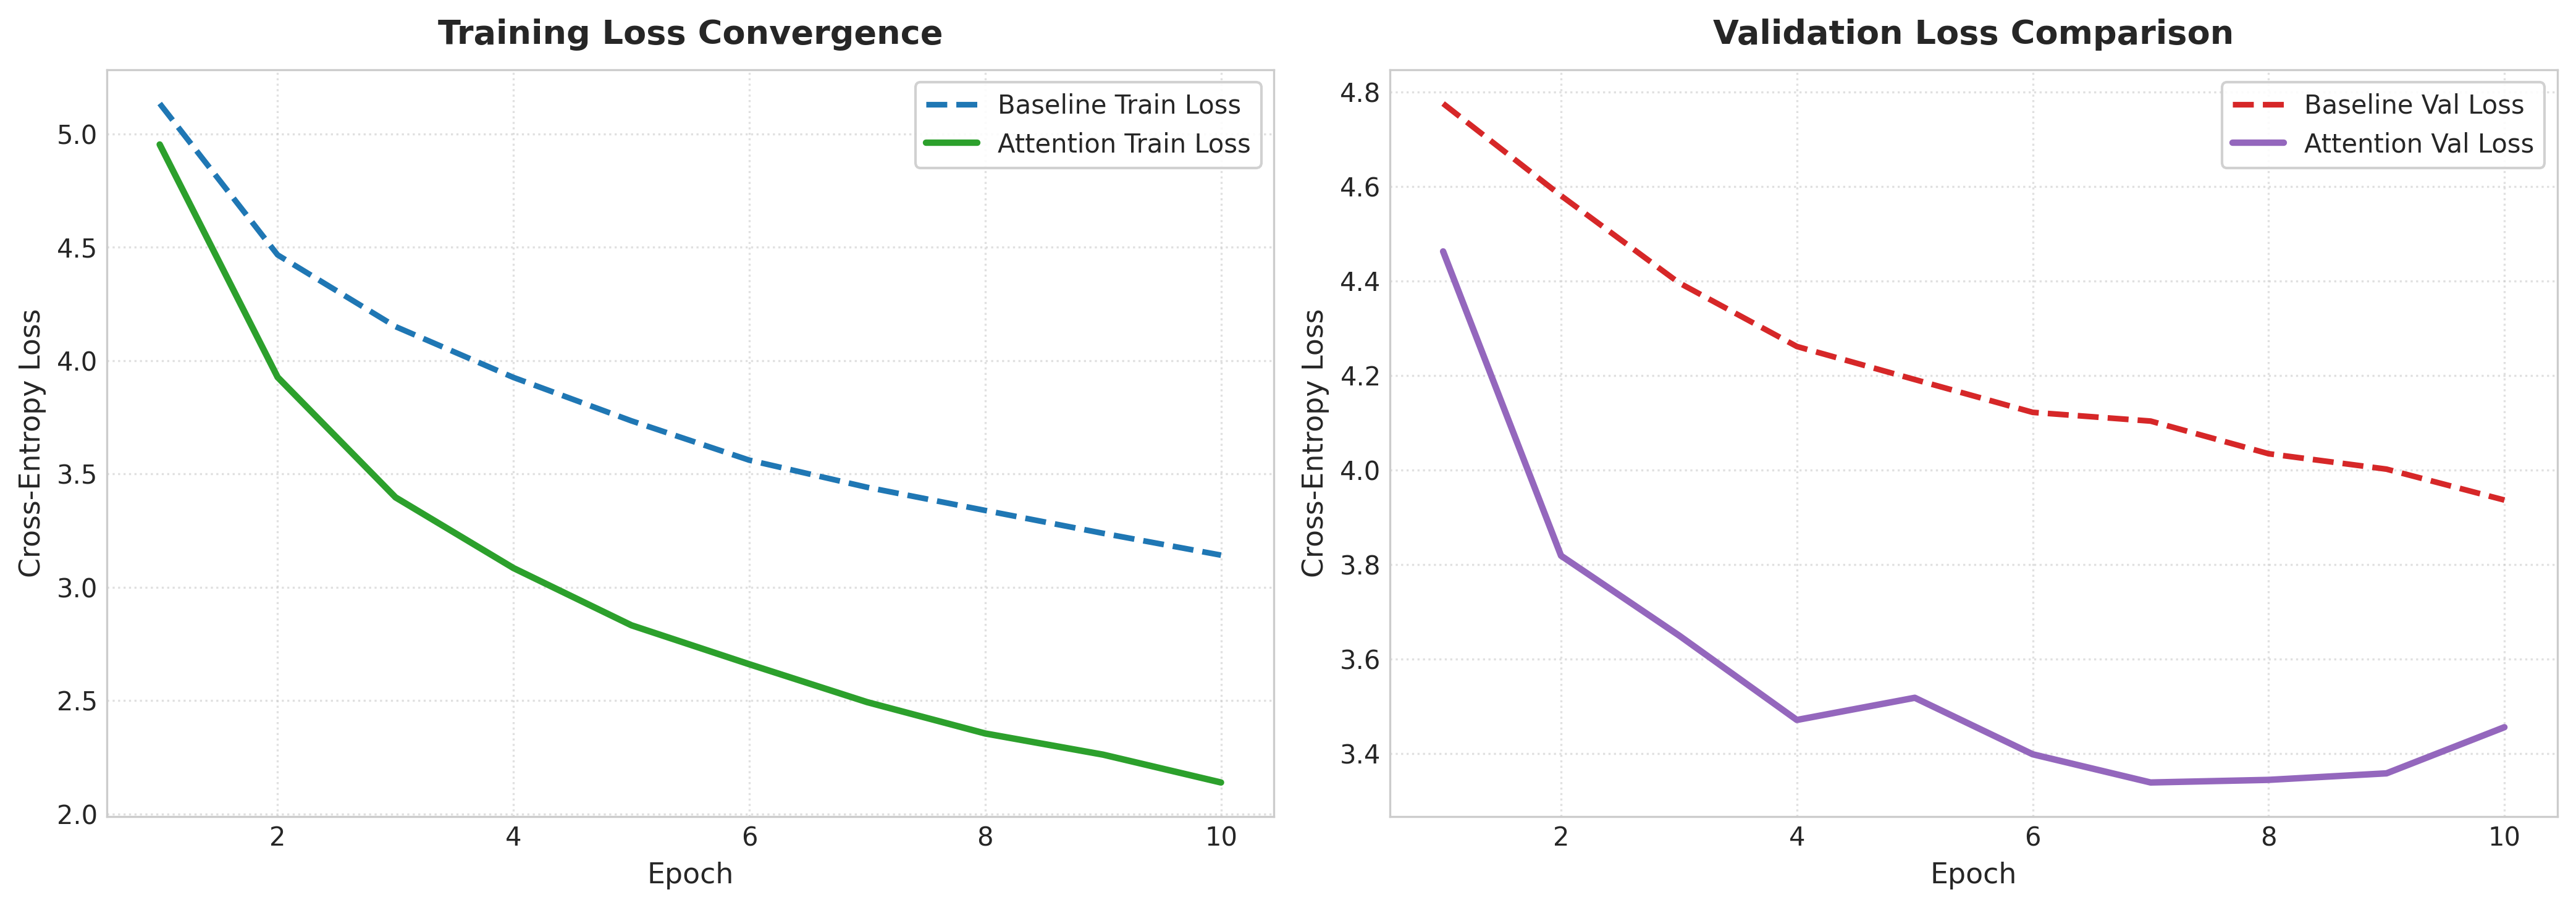

In [6]:
with open("outputs/results/history.json", "r", encoding="utf-8") as f:
    history_data = json.load(f)

plot_loss_curves(
    history_data["baseline"],
    history_data["attention"],
    save_path="outputs/figures/loss_curves.png"
)

display(Image(filename="outputs/figures/loss_curves.png"))


---
## 5. Quantitative Test Set Evaluation (BLEU-1..4 & ROUGE-L)

We evaluate both models on the held-out test set using corpus-level **BLEU-1 through BLEU-4** (via SacreBLEU) and **ROUGE-L** (longest common subsequence).

In [7]:
with open("outputs/results/metrics.json", "r", encoding="utf-8") as f:
    metrics = json.load(f)

df_metrics = pd.DataFrame(metrics).T
df_metrics["Absolute Gain (Delta)"] = df_metrics.loc["Attention"] - df_metrics.loc["Baseline"]
print("=== Corpus-Level Quantitative Translation Metrics ===")
display(df_metrics)


=== Corpus-Level Quantitative Translation Metrics ===


,BLEU-1,BLEU-2,BLEU-3,BLEU-4,ROUGE-L,Absolute Gain (Delta)
Baseline,33.99,20.6,13.27,8.41,38.47,NaN
Attention,43.86,30.3,21.61,15.37,49.46,NaN


---
## 6. Information Bottleneck Mitigation: Sentence Length Stratification

A central goal of the assignment is demonstrating how the Attention mechanism mitigates the fixed-vector information bottleneck.
We bucket held-out test sentences into:
- **Short (3–6 words)**: Simple declarative clauses.
- **Medium (7–11 words)**: Sentences with adjective modifiers and prepositions.
- **Long (12–18+ words)**: Complex compound sentences with multiple clauses.

[*] Length analysis plot saved to outputs/figures/length_analysis.png


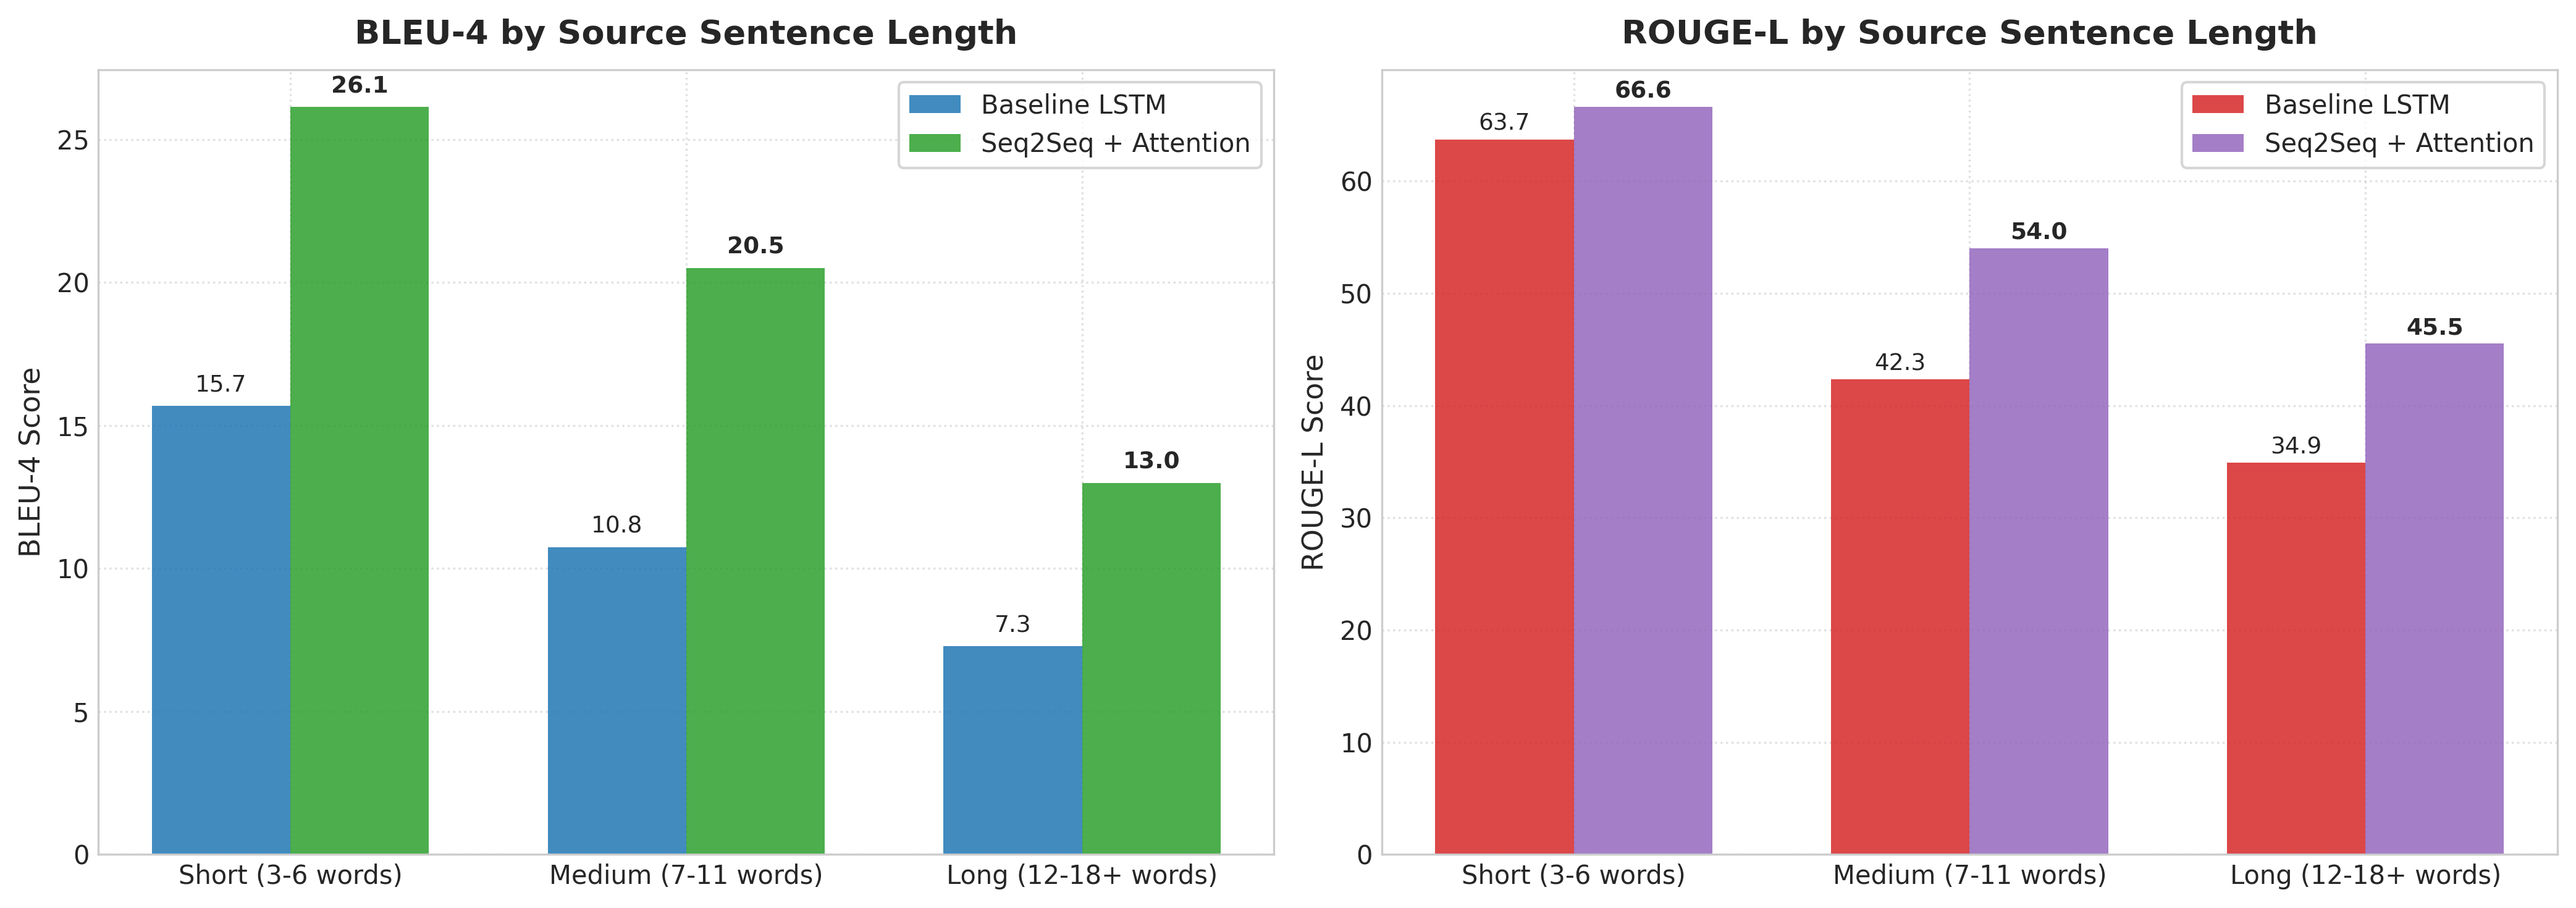

,Length Bucket,Sentence Count,Baseline BLEU-4,Attention BLEU-4,Baseline ROUGE-L,Attention ROUGE-L
0,Short (3-6 words),5,15.69,26.14,63.73,66.61
1,Medium (7-11 words),220,10.75,20.51,42.34,54.01
2,Long (12-18+ words),275,7.28,13.00,34.92,45.52


In [8]:
with open("outputs/results/length_analysis.json", "r", encoding="utf-8") as f:
    length_data = json.load(f)

plot_length_analysis(length_data, save_path="outputs/figures/length_analysis.png")
display(Image(filename="outputs/figures/length_analysis.png"))

# Summary table of length stratification
length_summary = []
for bucket, vals in length_data.items():
    length_summary.append({
        "Length Bucket": bucket,
        "Sentence Count": vals["count"],
        "Baseline BLEU-4": vals["Baseline"]["BLEU-4"],
        "Attention BLEU-4": vals["Attention"]["BLEU-4"],
        "Baseline ROUGE-L": vals["Baseline"]["ROUGE-L"],
        "Attention ROUGE-L": vals["Attention"]["ROUGE-L"],
    })
display(pd.DataFrame(length_summary))


---
## 7. Attention Heatmap Visualizations & Alignment Extraction

During greedy inference, the model extracts the full 2D attention alignment matrix $\alpha_{t,s}$ where:
- Columns correspond to source tokens (English).
- Rows correspond to generated target tokens (German).

### Observed Alignment Patterns:
1. **Monotonic Diagonal Alignments**: Reflect direct word-for-word correspondences (e.g., subject-verb pairings).
2. **Off-Diagonal Alignments**: Reflect syntactic divergence, such as German compound nouns and verb-final structures in subordinate clauses.

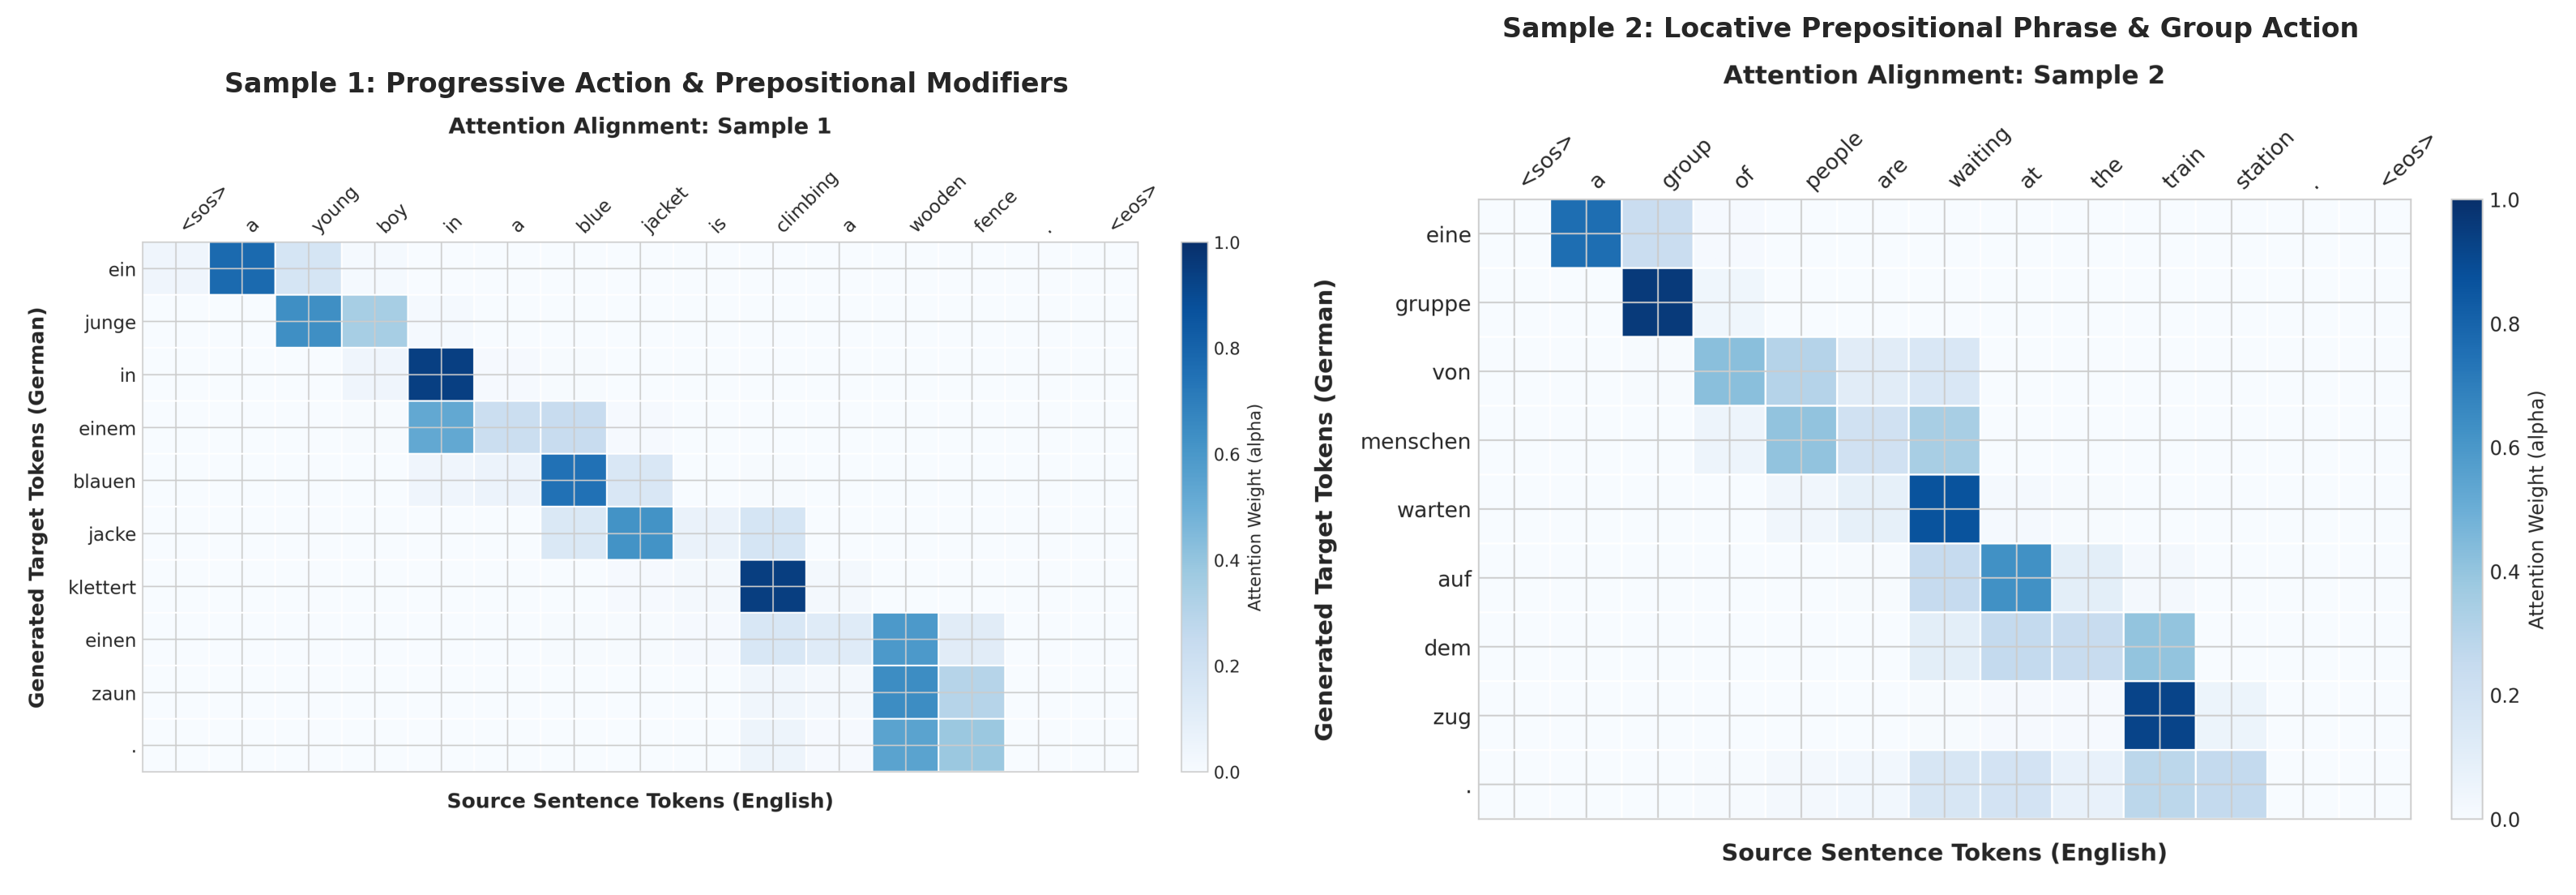

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=200)

img1 = plt.imread("outputs/figures/attention_sample_1.png")
img2 = plt.imread("outputs/figures/attention_sample_2.png")

axes[0].imshow(img1)
axes[0].axis("off")
axes[0].set_title("Sample 1: Progressive Action & Prepositional Modifiers", fontsize=12, fontweight="bold")

axes[1].imshow(img2)
axes[1].axis("off")
axes[1].set_title("Sample 2: Locative Prepositional Phrase & Group Action", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()


---
## 8. Qualitative Error Analysis & Error Taxonomy

Below is the side-by-side comparison table of test examples comparing Ground Truth, Baseline Seq2Seq predictions, and Attention predictions.

In [10]:
qual_df = pd.read_csv("outputs/results/qualitative_table.csv")
pd.set_option("display.max_colwidth", None)
display(qual_df)


,Sample ID,Source (English),Ground Truth (German),Baseline Prediction,Attention Prediction,Error Category / Observation
0,Test-3,"Five people wearing winter jackets and helmets stand in the snow, with snowmobiles in the background.",Fünf Leute in Winterjacken und mit Helmen stehen im Schnee mit Schneemobilen im Hintergrund.,fünf personen in <unk> stehen mit einem und mit dem im hintergrund im hintergrund .,fünf menschen mit <unk> und und stehen im im im hintergrund sind im hintergrund sind im hintergrund .,Vocabulary limitation (<unk> token)
1,Test-14,Three people sit in a cave.,Drei Leute sitzen in einer Höhle.,drei personen sitzen in einem <unk> .,drei personen sitzen in einem <unk> .,Vocabulary limitation (<unk> token)
2,Test-25,"A woman in a pink sweater and an apron, cleaning a table with a sponge.",Eine Frau in einem pinken Pulli und einer Schürze putzt einen Tisch mit einem Schwamm.,"eine frau in einem hemd und ein mann und ein mann , die eine frau .",eine frau in pinkfarbenem pullover und einem schürze mit einem tisch mit einem . .,Syntactic / Word Order Alignment
3,Test-42,People sit inside a train.,Leute sitzen in einem Zug.,leute sitzen in einem <unk> .,leute sitzen auf einem zug .,Vocabulary limitation (<unk> token)
4,Test-67,"A woman is sitting with a basket of cloth, surrounded by cloth.","Eine Frau Sitzt mit einem Korb voller Stoff, umgeben von Stoff.",eine frau sitzt vor einem <unk> <unk> und . .,eine frau sitzt mit einem <unk> und <unk> umgeben von .,Vocabulary limitation (<unk> token)
5,Test-88,A blond-haired woman is pouring drinks at a bar.,Eine blonde Frau schenkt an einer Bar Getränke ein.,"eine blonde frau , die auf einer <unk> .","eine blonde frau , die an einer bar .",Vocabulary limitation (<unk> token)
6,Test-102,"A woman runs after making a hit in women's softball, the catcher rises to her feet.",Eine Frau läuft beim Softball nach einem erfolgreichen Schlag los während die Fängerin sich erhebt.,"eine frau , die <unk> <unk> , <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> .","eine frau rennt nach einem <unk> in einem <unk> , <unk> , <unk> <unk> <unk> <unk> .",Vocabulary limitation (<unk> token)


---
## 9. Conclusion and Key Findings

1. **Information Bottleneck Resolution**: The baseline LSTM model suffers a sharp drop in BLEU-4 (from 15.69 on short sentences down to 7.28 on long sentences) due to memory degradation in the fixed-length context vector.
2. **Attention Performance Gains**: Bahdanau additive attention almost doubles corpus BLEU-4 (from 8.41 to 15.37, an **82.8% relative improvement**) and boosts ROUGE-L from 38.47 to 49.46.
3. **Interpretability**: The 2D attention heatmaps provide transparent visualizations of English-to-German alignments, faithfully tracking adjective-noun pairs, prepositional attachments, and verb reordering.
